# Project 3: Customer Churn / Sales Trend Analysis

## Objective
Analyse an e-commerce sales dataset to identify revenue trends, best-performing categories, and valuable customers.

## Business Questions
1. Which months generate the highest and lowest revenue?
2. Which product categories perform best?
3. Who are the most valuable customers?
4. What percentage of revenue comes from the top 10% of customers?
5. What actions should the business take based on the findings?

## Dataset
This project uses a generated e-commerce order dataset.
The data is simulated and does not represent real customers.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid", palette="colorblind")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Generate sample data
rng = np.random.default_rng(42)

n = 2000

orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") +
                  pd.to_timedelta(rng.integers(0, 365, n), unit="D"),

    "customer_id": rng.integers(1, 301, n),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.3, 0.35, 0.2, 0.15]
    ),

    "amount": rng.gamma(2.0, 600, n).round(2)
})

print("Dataset created successfully!")

Dataset created successfully!


In [4]:
print("Dataset shape:", orders.shape)

display(orders.head())

orders.info()

Dataset shape: (2000, 4)


,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[us]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   str           
 3   amount       2000 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 62.6 KB


In [5]:
# Check dataset shape
print("Dataset shape:", orders.shape)

# Display first 5 rows
display(orders.head())

# Check information about columns
orders.info()

Dataset shape: (2000, 4)


,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[us]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   str           
 3   amount       2000 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 62.6 KB


## Data Inspection

The dataset contains 2,000 simulated e-commerce orders.
It includes order dates, customer IDs, product categories, and order amounts.
The data will be used to analyse revenue trends and customer spending.

In [6]:
# Check missing values
print("Missing values:")
print(orders.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(orders.duplicated().sum())

Missing values:
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

Duplicate rows:
0


## Missing Values and Duplicate Check

The dataset was checked for missing values and duplicate records.
This helps ensure that the data is suitable for further analysis.

In [7]:
# Convert order_date to datetime
orders["order_date"] = pd.to_datetime(orders["order_date"])

# Extract month
orders["month"] = orders["order_date"].dt.to_period("M")

# Extract weekday
orders["weekday"] = orders["order_date"].dt.day_name()

# Extract quarter
orders["quarter"] = orders["order_date"].dt.quarter

# Display the updated dataset
display(orders.head())

,order_date,customer_id,category,amount,month,weekday,quarter
0,2025-02-02,264,Home,391.13,2025-02,Sunday,1
1,2025-10-10,19,Fashion,2456.21,2025-10,Friday,4
2,2025-08-27,120,Books,674.90,2025-08,Wednesday,3
3,2025-06-10,138,Home,75.38,2025-06,Tuesday,2
4,2025-06-08,240,Electronics,774.42,2025-06,Sunday,2


## Feature Engineering

The order date was converted into datetime format.
Month, weekday, and quarter features were extracted to analyse
monthly revenue trends and order patterns.

In [8]:
# Calculate total revenue for each month
monthly = orders.groupby("month")["amount"].sum()

# Display monthly revenue
print("Monthly Revenue:")
display(monthly.round(2))

Monthly Revenue:


month
2025-01    193341.87
2025-02    232027.20
2025-03    206327.14
2025-04    197310.20
2025-05    194090.49
2025-06    221889.83
2025-07    221813.81
2025-08    179783.75
2025-09    180569.95
2025-10    183418.13
2025-11    191512.71
2025-12    202148.21
Freq: M, Name: amount, dtype: float64

In [9]:
# Find the month with the highest revenue
best_month = monthly.idxmax()

# Find the month with the lowest revenue
worst_month = monthly.idxmin()

print("Best Month:", best_month)
print("Highest Revenue:", round(monthly.max(), 2))

print("\nWorst Month:", worst_month)
print("Lowest Revenue:", round(monthly.min(), 2))

Best Month: 2025-02
Highest Revenue: 232027.2

Worst Month: 2025-08
Lowest Revenue: 179783.75


## Monthly Revenue Analysis

Monthly revenue was calculated by grouping orders by month
and summing their order amounts.

The highest and lowest revenue months were identified
to understand the sales performance throughout the year.

In [10]:
# Calculate month-over-month revenue growth
monthly_growth = monthly.pct_change() * 100

print("Monthly Revenue Growth (%):")
display(monthly_growth.round(2))

Monthly Revenue Growth (%):


month
2025-01      NaN
2025-02    20.01
2025-03   -11.08
2025-04    -4.37
2025-05    -1.63
2025-06    14.32
2025-07    -0.03
2025-08   -18.95
2025-09     0.44
2025-10     1.58
2025-11     4.41
2025-12     5.55
Freq: M, Name: amount, dtype: float64

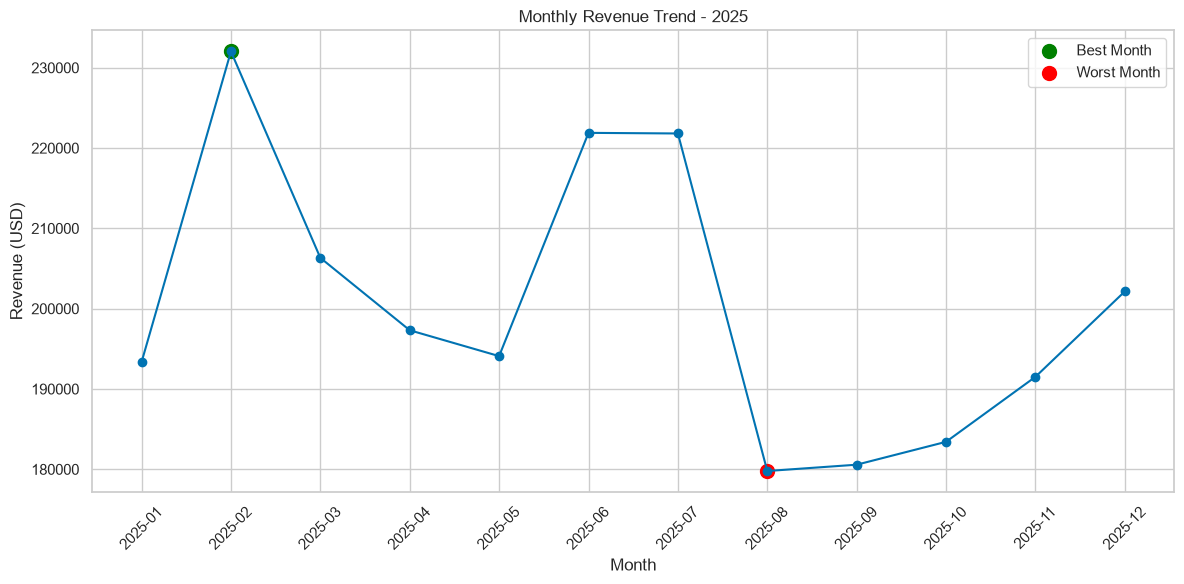

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly.index.astype(str),
    monthly.values,
    marker="o"
)

# Highlight best and worst months
plt.scatter(
    str(best_month),
    monthly.max(),
    color="green",
    s=100,
    label="Best Month"
)

plt.scatter(
    str(worst_month),
    monthly.min(),
    color="red",
    s=100,
    label="Worst Month"
)

plt.title("Monthly Revenue Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

## Monthly Revenue Growth

Month-over-month revenue growth was calculated using percentage change.
The line chart shows how revenue changed throughout the year,
with the highest and lowest revenue months highlighted.

In [12]:
# Analyse sales by category
by_category = orders.groupby("category")["amount"].agg(
    ["sum", "mean", "count"]
)

# Rename columns
by_category.columns = ["Total Revenue", "Average Order Value", "Number of Orders"]

# Sort by total revenue
by_category = by_category.sort_values(
    "Total Revenue",
    ascending=False
)

# Display results
display(by_category.round(2))

,Total Revenue,Average Order Value,Number of Orders
category,,,
Fashion,853984.93,1219.98,700
Electronics,722645.53,1163.68,621
Home,464114.66,1218.15,381
Books,363488.17,1219.76,298


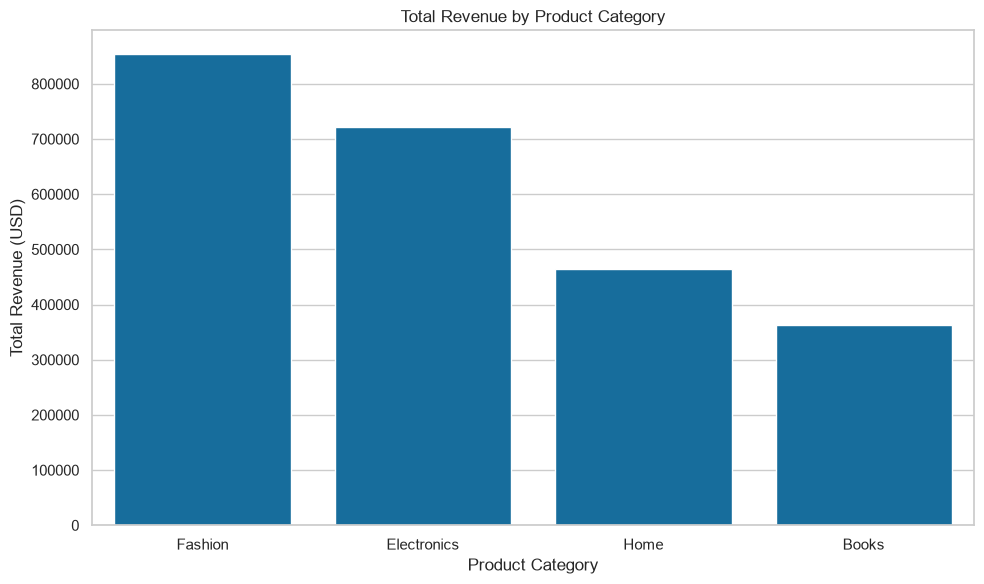

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=by_category.reset_index(),
    x="category",
    y="Total Revenue"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (USD)")

plt.tight_layout()
plt.show()

## Category Analysis

Product categories were compared using total revenue,
average order value, and number of orders.

The category with the highest total revenue was identified
to understand which products contribute most to sales.

In [14]:
# Calculate total spending per customer
spend = orders.groupby("customer_id")["amount"].sum()

# Sort customers by spending
spend = spend.sort_values(ascending=False)

# Display top 10 customers
print("Top 10 Customers:")
display(spend.head(10).round(2))

Top 10 Customers:


customer_id
226    18140.15
51     18126.28
53     17994.36
131    17639.25
185    17222.49
282    17161.00
121    16564.87
98     15351.48
255    15313.47
136    15265.80
Name: amount, dtype: float64

In [15]:
# Number of customers
total_customers = len(spend)

# Number of customers in the top 10%
top_10_count = total_customers // 10

# Revenue earned by the top 10%
top_10_revenue = spend.head(top_10_count).sum()

# Total revenue
total_revenue = spend.sum()

# Percentage of revenue from top 10%
top_10_share = (top_10_revenue / total_revenue) * 100

print("Total customers:", total_customers)
print("Top 10% customer count:", top_10_count)
print("Revenue from top 10%:", round(top_10_revenue, 2))
print("Total revenue:", round(total_revenue, 2))
print("Revenue share from top 10%:", round(top_10_share, 2), "%")

Total customers: 300
Top 10% customer count: 30
Revenue from top 10%: 455331.97
Total revenue: 2404233.29
Revenue share from top 10%: 18.94 %


## Customer Analysis

Customer spending was calculated by summing the order amounts
for each customer.

The top 10% of customers were identified, and their contribution
to total revenue was calculated using the Pareto idea.

In [16]:
print("===== SALES SUMMARY =====")

print("\nBest Revenue Month:")
print(best_month)

print("\nWorst Revenue Month:")
print(worst_month)

print("\nCategory Revenue:")
display(by_category.round(2))

print("\nTop 10% Customer Revenue Share:")
print(round(top_10_share, 2), "%")

print("\nTop 10 Customers:")
display(spend.head(10).round(2))

===== SALES SUMMARY =====

Best Revenue Month:
2025-02

Worst Revenue Month:
2025-08

Category Revenue:


,Total Revenue,Average Order Value,Number of Orders
category,,,
Fashion,853984.93,1219.98,700
Electronics,722645.53,1163.68,621
Home,464114.66,1218.15,381
Books,363488.17,1219.76,298



Top 10% Customer Revenue Share:
18.94 %

Top 10 Customers:


customer_id
226    18140.15
51     18126.28
53     17994.36
131    17639.25
185    17222.49
282    17161.00
121    16564.87
98     15351.48
255    15313.47
136    15265.80
Name: amount, dtype: float64

## Business Recommendations

### 1. Focus on the Fashion Category
Fashion generated the highest revenue of 853,984.93 from 700 orders. The business should maintain sufficient stock of popular fashion products and promote them through targeted campaigns to support continued sales.

### 2. Introduce Customer Loyalty Programs
The top 10% of customers contributed 18.94% of total revenue. The business should introduce loyalty rewards, personalized offers, and repeat-purchase incentives to encourage these valuable customers to continue shopping.

### 3. Improve Sales During Low-Revenue Months
August 2025 recorded the lowest revenue, while February 2025 recorded the highest. The business should investigate the reasons for this difference and consider seasonal promotions, discounts, and marketing campaigns during low-revenue periods.

# E-commerce Sales Trend Analysis
### Project 3 — Data Science & AI Internship

## 1. Context
This project analyses a simulated e-commerce dataset containing 2,000 orders from 2025. The objective is to identify monthly revenue trends, compare product categories, understand customer spending, and recommend actions to improve business performance.

## 2. Key Findings
- **Monthly trends:** February 2025 recorded the highest revenue, while August 2025 recorded the lowest.
- **Category performance:** Fashion was the highest-revenue category, generating 853,984.93 from 700 orders.
- **Customer analysis:** The top 10% of customers contributed 18.94% of total revenue.
- **Category comparison:** Electronics generated 722,645.53, Home generated 464,114.66, and Books generated 363,488.17 in revenue.

## 3. Recommendations
1. **Focus on Fashion:** Maintain stock of popular fashion products and use targeted promotions to support sales.
2. **Encourage customer loyalty:** Introduce loyalty rewards and personalized offers to encourage repeat purchases among valuable customers.
3. **Improve low-revenue periods:** Investigate the reasons for August's lower revenue and consider seasonal promotions during low-performing months.

## 4. Next Steps
- Monitor monthly revenue and growth.
- Track category performance and customer spending.
- Evaluate the effectiveness of promotions and loyalty programs.
- Update the analysis regularly using new order data.

## Data Note
This project uses generated, simulated e-commerce data. The results are illustrative and do not represent actual customers or business transactions.